# Rodinné zázemí a výsledky v přírodních vědách

Autor: Vojtěch Pardubský

Analytická otázka:
Které kombinace rodinného zázemí, klidného místa na učení
a podpory rodiny souvisejí s vyšší úrovní Science?

In [3]:
from pathlib import Path
import json
import pandas as pd
import pyarrow.parquet as pq

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent

DATA = PROJECT / "data/processed/student_full.parquet"
METADATA = PROJECT / "data/processed/student_full_metadata.json"
if not DATA.is_file() or not METADATA.is_file():
    raise FileNotFoundError("Najprv priprav plný Parquet podľa kroku 5 v README.")

metadata = json.loads(METADATA.read_text(encoding="utf-8"))
parquet = pq.ParquetFile(DATA)
if json.loads(parquet.schema_arrow.metadata[b"pisa_metadata"]) != metadata:
    raise ValueError("Parquet a metadata JSON nepatria k sebe. Použi oba súbory z rovnakého prevodu.")
print(f"Záznamy: {parquet.metadata.num_rows:,}")
print(f"Premenné: {parquet.metadata.num_columns}")

Záznamy: 755,721
Premenné: 885


In [4]:
PREDICTORS = [
    "ESCS",        # Celkové socioekonomické zázemí
    "HISCED",      # Nejvyšší vzdělání rodičů
    "HISEI",       # Nejvyšší profesní status rodičů
    "ST255Q01JA",  # Počet knih doma
    "ST250Q20DA",  # Klidné místo na učení
    "FAMSUP",      # Podpora rodiny
]

SCIENCE = [f"PV{i}SCIE" for i in range(1, 11)]

COLUMNS = [
    "CNT",
    "CNTSTUID",
    "CNTSCHID",
    "W_FSTUWT",
] + PREDICTORS + SCIENCE

df = pd.read_parquet(DATA, columns=COLUMNS)

print("Rozměry:", df.shape)
display(df.head())

Rozměry: (755721, 20)


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,ESCS,HISCED,HISEI,ST255Q01JA,ST250Q20DA,FAMSUP,PV1SCIE,PV2SCIE,PV3SCIE,PV4SCIE,PV5SCIE,PV6SCIE,PV7SCIE,PV8SCIE,PV9SCIE,PV10SCIE
0,ALB,00800001,00800001,2.579892,-1.100674,5.0,24.53,2.0,1.0,-0.695292,289.678433,330.597936,309.055305,277.581017,325.553250,287.138669,337.102788,349.289918,307.361007,390.022587
1,ALB,00800002,00800001,2.681028,-1.930787,1.0,999.00,3.0,2.0,0.108956,416.224453,417.555856,441.775936,464.852289,402.777962,417.029018,403.722062,436.374077,424.595626,405.076019
2,ALB,00800003,00800001,2.681028,-1.078518,6.0,999.00,2.0,1.0,-0.612272,488.596531,505.993468,521.443964,518.727129,521.368052,461.968818,457.995818,468.754931,502.829241,473.339264
3,ALB,00800004,00800001,2.681028,-0.018204,5.0,71.39,2.0,1.0,1.695762,326.012761,370.805787,411.779320,357.517514,358.449328,391.240711,395.631141,402.996271,381.864843,385.258321
4,ALB,00800005,00800001,2.681028,-1.071648,5.0,25.95,3.0,1.0,1.695762,348.666297,389.462758,391.818381,425.777393,420.731024,393.301439,428.754786,400.000531,424.450703,387.240444


In [5]:
by_name = {
    column["name"]: column
    for column in metadata["columns"]
}

df_clean = df.copy()

for name in COLUMNS:
    for interval in by_name[name]["missing_ranges"]:
        lo, hi = interval["lo"], interval["hi"]
        mask = df_clean[name].between(lo, hi)
        df_clean.loc[mask, name] = None

missing_overview = pd.DataFrame({
    "Chybějící počet": df_clean.isna().sum(),
    "Chybějící %": df_clean.isna().mean().mul(100).round(2),
})

display(missing_overview)

,Chybějící počet,Chybějící %
CNT,0,0.00
CNTSTUID,0,0.00
CNTSCHID,25758,3.41
W_FSTUWT,0,0.00
ESCS,74677,9.88
HISCED,110532,14.63
HISEI,175344,23.20
ST255Q01JA,32538,4.31
ST250Q20DA,337284,44.63
FAMSUP,110693,14.65


In [6]:
# Dvě uvažované varianty vysvětlujících proměnných
VAR_A = ["ESCS", "ST250Q20DA", "FAMSUP"]
VAR_B = ["HISCED", "HISEI", "ST255Q01JA", "ST250Q20DA", "FAMSUP"]

availability = pd.DataFrame({
    "CNT": df_clean["CNT"],
    "kompletni_A": df_clean[VAR_A + SCIENCE].notna().all(axis=1),
    "kompletni_B": df_clean[VAR_B + SCIENCE].notna().all(axis=1),
    "spolecny_vzorek": df_clean[PREDICTORS + SCIENCE].notna().all(axis=1),
})

country_overview = availability.groupby("CNT").agg(
    celkem=("CNT", "size"),
    kompletni_A=("kompletni_A", "sum"),
    kompletni_B=("kompletni_B", "sum"),
    spolecny_vzorek=("spolecny_vzorek", "sum"),
)

country_overview["spolecny_vzorek_pct"] = (
    100 * country_overview["spolecny_vzorek"] / country_overview["celkem"]
).round(1)

display(
    country_overview.sort_values("spolecny_vzorek", ascending=False).head(30)
)

,celkem,kompletni_A,kompletni_B,spolecny_vzorek,spolecny_vzorek_pct
CNT,,,,,
ARE,34639,29162,23808,23808,68.7
BRA,30140,22211,17961,17961,59.6
QCI,12385,12253,11293,11293,91.2
GBR,15546,12857,10650,10650,68.5
ECU,9128,8222,7553,7553,82.7
THA,8547,8027,6849,6849,80.1
TAP,7279,7025,6456,6456,88.7
MYS,7624,7164,6320,6320,82.9
FIN,7668,6769,6172,6172,80.5


In [7]:
# Pracovní volba; změň, pokud máte v týmu dohodnutý jiný rozsah.
COUNTRIES = ["GBR"]

df_scope = df_clean.loc[
    df_clean["CNT"].isin(COUNTRIES)
].copy()

# Stejní studenti pro variantu A i B
required = PREDICTORS + SCIENCE
complete = df_scope[required].notna().all(axis=1)

df_analysis = df_scope.loc[complete].copy()

print("Původní počet:", len(df_scope))
print("Společný analytický vzorek:", len(df_analysis))
print("Zachováno (%):", round(100 * complete.mean(), 1))

print(
    "Duplicitní identifikátory:",
    df_analysis.duplicated(["CNT", "CNTSTUID"]).sum()
)

print(
    "Chybějící nebo nekladné váhy:",
    (
        df_analysis["W_FSTUWT"].isna()
        | df_analysis["W_FSTUWT"].le(0)
    ).sum()
)

Původní počet: 15546
Společný analytický vzorek: 10650
Zachováno (%): 68.5
Duplicitní identifikátory: 0
Chybějící nebo nekladné váhy: 0


In [8]:
for name in ["HISCED", "ST255Q01JA", "ST250Q20DA"]:
    print(f"\n{name}: {by_name[name]['label']}")
    display(pd.DataFrame(by_name[name]["value_labels"]))

    display(
        df_analysis[name]
        .value_counts(dropna=False)
        .sort_index()
        .rename("pocet")
        .to_frame()
    )

display(
    df_analysis[["ESCS", "HISEI", "FAMSUP"]]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .T
)


HISCED: Highest educational level of parent(s)/guardian(s)


,value,label
0,1.0,parent does not have any of these qualifications
1,2.0,ISCED Level 2 (Lower secondary education)
2,3.0,ISCED Level 3.3 (Upper secondary education wit...
3,4.0,ISCED Level 3.4 (Upper secondary education of ...
4,5.0,ISCED Level 4 (Post-secondary non-tertiary edu...
5,6.0,ISCED Level 5 (Short-cycle tertiary education)
6,7.0,ISCED Level 6 (Bachelor’s or equivalent)
7,8.0,ISCED Level 7 (Master's or equivalent)
8,9.0,ISCED Level 8 (Doctoral or equivalent)
9,95.0,valid skip (filter rule)


,pocet
HISCED,
1.0,436
2.0,168
3.0,1509
4.0,1168
5.0,849
6.0,710
7.0,2875
8.0,1932
9.0,1003



ST255Q01JA: How many books are there in your <home>?


,value,label
0,1.0,There are no books
1,2.0,1-10 books
2,3.0,11-25 books
3,4.0,26-100 books
4,5.0,101-200 books
5,6.0,201-500 books
6,7.0,More than 500 books
7,95.0,valid skip (filter rule)
8,96.0,system missing
9,97.0,not administered/not applicable


,pocet
ST255Q01JA,
1.0,317
2.0,1539
3.0,1966
4.0,3268
5.0,1772
6.0,1244
7.0,544



ST250Q20DA: Which of the following are in your <home>? - A quiet place/room to study


,value,label
0,1.0,Yes
1,2.0,No
2,5.0,valid skip (filter rule)
3,6.0,system missing
4,7.0,not administered/not applicable
5,8.0,invalid
6,9.0,no response


,pocet
ST250Q20DA,
1.0,8895
2.0,1755


,count,mean,std,min,25%,50%,75%,max
ESCS,10650.0,0.242995,0.936286,-3.467313,-0.409613,0.381687,0.985580,3.386681
HISEI,10650.0,58.869920,21.262137,11.740000,39.020000,68.550000,76.490000,88.960000
FAMSUP,10650.0,-0.062217,0.917348,-2.592633,-0.640650,-0.125085,0.377538,1.695762


## Kategorizace vysvětlujících proměnných

Analýza používá společný vzorek 10 650 studentů z GBR.

ESCS, profesní status rodičů a rodinnou podporu rozdělujeme
podle neváženého 25. a 75. percentilu analytického vzorku.
Kategorie označují relativní postavení v tomto vzorku,
nikoli oficiální úrovně OECD.

Vzdělání rodičů a počet knih seskupujeme podle významu odpovědí.
Klidné místo na učení zachováváme jako ano/ne.

Hranice stanovujeme před hledáním pravidel a používáme je
shodně v obou variantách analýzy.

In [9]:
import numpy as np

df_cat = pd.DataFrame(index=df_analysis.index)
boundaries = []

# Číselné indexy: nižší / střední / vyšší
for source, target in [
    ("ESCS", "zazemi"),
    ("HISEI", "profesni_status"),
    ("FAMSUP", "podpora_rodiny"),
]:
    q25, q75 = df_analysis[source].quantile([0.25, 0.75])

    if q25 >= q75:
        raise ValueError(f"{source}: nelze vytvořit tři odlišné intervaly.")

    df_cat[target] = pd.cut(
        df_analysis[source],
        bins=[-np.inf, q25, q75, np.inf],
        labels=["nizsi", "stredni", "vyssi"],
        right=True,
    )

    boundaries.append({
        "promenna": source,
        "hranice_nizsi_stredni": q25,
        "hranice_stredni_vyssi": q75,
    })

# Nejvyšší vzdělání rodičů
education_map = {
    1: "nejvyse_nizsi_sekundarni",
    2: "nejvyse_nizsi_sekundarni",
    3: "vyssi_sekundarni_a_postsekundarni_neterciarni",
    4: "vyssi_sekundarni_a_postsekundarni_neterciarni",
    5: "vyssi_sekundarni_a_postsekundarni_neterciarni",
    6: "terciarni",
    7: "terciarni",
    8: "terciarni",
    9: "terciarni",
}

df_cat["vzdelani_rodicu"] = df_analysis["HISCED"].map(education_map)

# Počet knih doma
books_map = {
    1: "0_25",
    2: "0_25",
    3: "0_25",
    4: "26_100",
    5: "vice_nez_100",
    6: "vice_nez_100",
    7: "vice_nez_100",
}

df_cat["knihy"] = df_analysis["ST255Q01JA"].map(books_map)

# Klidné místo na učení
df_cat["klidne_misto"] = df_analysis["ST250Q20DA"].map({
    1: "ano",
    2: "ne",
})

if df_cat.isna().any().any():
    raise ValueError("Po kategorizaci vznikly chybějící hodnoty.")

category_boundaries = pd.DataFrame(boundaries)
display(category_boundaries)
display(df_cat.head())

,promenna,hranice_nizsi_stredni,hranice_stredni_vyssi
0,ESCS,-0.409613,0.985580
1,HISEI,39.020000,76.490000
2,FAMSUP,-0.640650,0.377538


,zazemi,profesni_status,podpora_rodiny,vzdelani_rodicu,knihy,klidne_misto
714597,nizsi,nizsi,stredni,terciarni,0_25,ne
714598,stredni,vyssi,stredni,terciarni,26_100,ano
714599,stredni,vyssi,stredni,terciarni,vice_nez_100,ne
714600,stredni,vyssi,stredni,terciarni,vice_nez_100,ano
714606,vyssi,stredni,nizsi,terciarni,26_100,ano


In [10]:
for name in df_cat.columns:
    counts = df_cat[name].value_counts(sort=False)

    overview = pd.DataFrame({
        "pocet": counts,
        "podil_pct": (100 * counts / len(df_cat)).round(1),
    })

    print(f"\n{name}")
    display(overview)


zazemi


,pocet,podil_pct
zazemi,,
nizsi,2663,25.0
stredni,5324,50.0
vyssi,2663,25.0



profesni_status


,pocet,podil_pct
profesni_status,,
nizsi,2669,25.1
stredni,5455,51.2
vyssi,2526,23.7



podpora_rodiny


,pocet,podil_pct
podpora_rodiny,,
nizsi,2663,25.0
stredni,5332,50.1
vyssi,2655,24.9


... (2 outputs left out)


knihy


,pocet,podil_pct
knihy,,
0_25,3822,35.9
26_100,3268,30.7
vice_nez_100,3560,33.4



klidne_misto


,pocet,podil_pct
klidne_misto,,
ne,1755,16.5
ano,8895,83.5


In [11]:
science_summary = df_analysis[SCIENCE].describe(
    percentiles=[0.25, 0.5, 0.75]
).T

display(science_summary)

,count,mean,std,min,25%,50%,75%,max
PV1SCIE,10650.0,520.681777,97.668991,204.000915,453.073500,521.916856,589.350036,832.062692
PV2SCIE,10650.0,520.936376,97.213892,173.592759,453.458656,522.096957,588.754230,846.572960
PV3SCIE,10650.0,521.141607,97.719511,199.703902,452.485268,521.936802,590.264260,833.217696
PV4SCIE,10650.0,521.372850,96.738690,188.127096,454.396697,522.564463,589.051649,860.586349
PV5SCIE,10650.0,520.890745,97.264710,194.165368,452.622490,522.120690,589.503543,834.255887
PV6SCIE,10650.0,520.930375,97.554531,186.645553,452.201861,522.792030,589.388623,885.832838
PV7SCIE,10650.0,520.808831,97.962901,169.191052,452.206658,521.795246,589.892865,858.461492
PV8SCIE,10650.0,521.691548,97.238693,174.432671,454.282788,522.300792,589.954133,832.489549
PV9SCIE,10650.0,521.662051,97.476478,183.198719,453.551442,521.762171,590.980794,846.034171
PV10SCIE,10650.0,521.020778,97.464173,205.611390,452.922687,521.903054,590.202445,822.685141


In [12]:
SCIENCE_THRESHOLD = float(df_analysis["PV1SCIE"].quantile(0.75))

df_rules = df_cat.copy()

df_rules["science"] = pd.Categorical(
    np.where(
        df_analysis["PV1SCIE"] > SCIENCE_THRESHOLD,
        "vyssi",
        "ostatni",
    ),
    categories=["vyssi", "ostatni"],
    ordered=True,
)

baseline = df_rules["science"].eq("vyssi").mean()

print(f"Hranice Science: > {SCIENCE_THRESHOLD:.6f}")
print(f"Výchozí podíl vyšší Science: {baseline:.2%}")
display(df_rules["science"].value_counts())

Hranice Science: > 589.350036
Výchozí podíl vyšší Science: 25.00%


science
ostatni    7987
vyssi      2663
Name: count, dtype: int64

In [14]:
%pip install cleverminer

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 2.1 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.3 MB 2.4 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.3 MB 2.6 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.3 MB 2.9 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 3.3 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 3.5 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 3.8 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 4.1 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 4.4 MB/s eta 0:00:01
   ------------------------------------

In [15]:
from cleverminer import cleverminer

Cleverminer version  1.2.8


In [16]:
ATTR_A = ["zazemi", "klidne_misto", "podpora_rodiny"]

clm_A = cleverminer(
    df=df_rules[ATTR_A + ["science"]].copy(),
    proc="4ftMiner",
    quantifiers={
        "Base": 100,
        "conf": 0.40,
    },
    ante={
        "attributes": [
            {
                "name": name,
                "type": "subset",
                "minlen": 1,
                "maxlen": 1,
            }
            for name in ATTR_A
        ],
        "minlen": 1,
        "maxlen": 3,
        "type": "con",
    },
    succ={
        "attributes": [
            {
                "name": "science",
                "type": "lcut",
                "minlen": 1,
                "maxlen": 1,
            }
        ],
        "minlen": 1,
        "maxlen": 1,
        "type": "con",
    },
)

clm_A.print_data_definition()
clm_A.print_summary()
clm_A.print_rulelist()

Cleverminer version 1.2.8.
Starting data preparation ...
Automatically reordering numeric categories ...
Automatically reordering numeric categories ...done
Encoding columns into bit-form...
Encoding columns into bit-form...done
Data preparation finished.
Will go for  4ftMiner
Starting to mine rules.
100%|####################################################|Elapsed Time: 0:00:00
Done. Total verifications : 34, rules 2, times: prep 0.01sec, processing 0.06sec
Dataset has 4 variables.
Variable zazemi has 3 categories: nizsi stredni vyssi
Variable klidne_misto has 2 categories: ano ne
Variable podpora_rodiny has 3 categories: nizsi stredni vyssi
Variable science has 2 categories: vyssi ostatni

CleverMiner task processing summary:

Task type : 4ftMiner
Number of verifications : 34
Number of rules : 2
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  CONF  AAD    Rule
     1   551 0.423 +0.691 zazemi(vyssi

In [17]:
ATTR_B = [
    "vzdelani_rodicu",
    "profesni_status",
    "knihy",
    "klidne_misto",
    "podpora_rodiny",
]

clm_B = cleverminer(
    df=df_rules[ATTR_B + ["science"]].copy(),
    proc="4ftMiner",
    quantifiers={
        "Base": 100,
        "conf": 0.40,
    },
    ante={
        "attributes": [
            {
                "name": name,
                "type": "subset",
                "minlen": 1,
                "maxlen": 1,
            }
            for name in ATTR_B
        ],
        "minlen": 1,
        "maxlen": 3,
        "type": "con",
    },
    succ={
        "attributes": [
            {
                "name": "science",
                "type": "lcut",
                "minlen": 1,
                "maxlen": 1,
            }
        ],
        "minlen": 1,
        "maxlen": 1,
        "type": "con",
    },
)

clm_B.print_summary()
clm_B.print_rulelist()

Cleverminer version 1.2.8.
Starting data preparation ...
Automatically reordering numeric categories ...
Automatically reordering numeric categories ...done
Encoding columns into bit-form...
Encoding columns into bit-form...done
Data preparation finished.
Will go for  4ftMiner
Starting to mine rules.
100%|####################################################|Elapsed Time: 0:00:00
Done. Total verifications : 148, rules 19, times: prep 0.02sec, processing 0.03sec

CleverMiner task processing summary:

Task type : 4ftMiner
Number of verifications : 148
Number of rules : 19
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  CONF  AAD    Rule
     1   597 0.408 +0.631 vzdelani_rodicu(terciarni) & profesni_status(stredni) & knihy(vice_nez_100) => science(vyssi) | ---
     2   537 0.490 +0.959 vzdelani_rodicu(terciarni) & profesni_status(vyssi) & knihy(vice_nez_100) => science(vyssi) | ---
     3   107 0.421 +0

In [18]:
clm_A.print_rule(2)
clm_B.print_rule(12)



Rule id : 2

Base :   596  Relative base : 0.056  CONF : 0.425  AAD : +0.699  BAD : -0.699

Cedents:
  antecedent : zazemi(vyssi) & podpora_rodiny(stredni)
  succcedent : science(vyssi)
  condition  : ---

Fourfold table
    |  S  |  ¬S |
----|-----|-----|
 A  |  596|  807|
----|-----|-----|
¬A  | 2067| 7180|
----|-----|-----|



Rule id : 12

Base :   361  Relative base : 0.034  CONF : 0.532  AAD : +1.129  BAD : -1.129

Cedents:
  antecedent : profesni_status(vyssi) & knihy(vice_nez_100) & podpora_rodiny(stredni)
  succcedent : science(vyssi)
  condition  : ---

Fourfold table
    |  S  |  ¬S |
----|-----|-----|
 A  |  361|  317|
----|-----|-----|
¬A  | 2302| 7670|
----|-----|-----|



In [19]:
rules_to_check = {
    "A2": {
        "zazemi": "vyssi",
        "podpora_rodiny": "stredni",
    },
    "B14": {
        "knihy": "vice_nez_100",
    },
    "B10": {
        "profesni_status": "vyssi",
        "knihy": "vice_nez_100",
    },
    "B12": {
        "profesni_status": "vyssi",
        "knihy": "vice_nez_100",
        "podpora_rodiny": "stredni",
    },
}

assert df_cat.index.equals(df_analysis.index)

weights = df_analysis["W_FSTUWT"]
rows = []

for rule_name, conditions in rules_to_check.items():
    mask = pd.Series(True, index=df_cat.index)

    for column, value in conditions.items():
        mask &= df_cat[column].eq(value)

    group_n = int(mask.sum())
    if group_n == 0:
        raise ValueError(f"Prázdná skupina: {rule_name}")

    for pv in SCIENCE:
        target = df_analysis[pv].gt(SCIENCE_THRESHOLD)

        base = int((mask & target).sum())
        confidence = base / group_n
        baseline = target.mean()

        weighted_baseline = (
            weights.loc[target].sum() / weights.sum()
        )
        weighted_confidence = (
            weights.loc[mask & target].sum()
            / weights.loc[mask].sum()
        )

        rows.append({
            "pravidlo": rule_name,
            "PV": pv,
            "pocet_ve_skupine": group_n,
            "base": base,
            "confidence": confidence,
            "lift": confidence / baseline,
            "confidence_vazena": weighted_confidence,
            "lift_vazeny": weighted_confidence / weighted_baseline,
            "splnuje_prahy": base >= 100 and confidence >= 0.40,
        })

robustness = pd.DataFrame(rows)

summary = robustness.groupby("pravidlo").agg(
    pocet_ve_skupine=("pocet_ve_skupine", "first"),
    conf_prumer=("confidence", "mean"),
    conf_min=("confidence", "min"),
    conf_max=("confidence", "max"),
    lift_prumer=("lift", "mean"),
    conf_vazena_prumer=("confidence_vazena", "mean"),
    lift_vazeny_prumer=("lift_vazeny", "mean"),
    pocet_PV_splnujicich_prahy=("splnuje_prahy", "sum"),
)

display(summary.round(3))

,pocet_ve_skupine,conf_prumer,conf_min,conf_max,lift_prumer,conf_vazena_prumer,lift_vazeny_prumer,pocet_PV_splnujicich_prahy
pravidlo,,,,,,,,
A2,1403,0.420,0.400,0.428,1.672,0.492,1.640,9
B10,1207,0.470,0.458,0.488,1.869,0.541,1.802,10
B12,678,0.515,0.496,0.544,2.051,0.587,1.955,10
B14,3560,0.405,0.396,0.416,1.612,0.469,1.563,9


In [20]:
table = pd.crosstab(
    df_cat["knihy"],
    df_rules["science"],
).reindex(
    index=["0_25", "26_100", "vice_nez_100"],
    columns=["vyssi", "ostatni"],
    fill_value=0,
)

table["celkem"] = table["vyssi"] + table["ostatni"]
table["vyssi_science_pct"] = (
    100 * table["vyssi"] / table["celkem"]
).round(1)

display(table)

science,vyssi,ostatni,celkem,vyssi_science_pct
knihy,,,,
0_25,453,3369,3822,11.9
26_100,772,2496,3268,23.6
vice_nez_100,1438,2122,3560,40.4


## Interpretace a závěr

Analyzovali jsme 10 650 studentů z GBR s kompletními údaji
pro obě varianty analýzy, tedy 68,5 % původního vzorku.

Vyšší Science jsme definovali jako skóre nad 589,350036 bodu,
což odpovídá 75. percentilu PV1SCIE analytického vzorku.
Nejde o oficiální úroveň PISA.

Při nastavení Base ≥ 100 a confidence ≥ 0,40 nalezl 4ft-Miner
2 pravidla ve variantě s ESCS a 19 pravidel ve variantě
s dílčími ukazateli rodinného zázemí. Vyšší počet pravidel
sám o sobě neznamená lepší výsledek; druhá varianta obsahovala
více vysvětlujících proměnných.

### Vybraná pravidla

Vyšší ESCS a střední rodinná podpora:
V PV1SCIE splňovalo podmínky pravidla 1 403 studentů,
z nichž 596 dosáhlo vyšší Science. Confidence byla 42,5 %.
Průměrná confidence přes deset PV byla 42,0 %.

Vyšší profesní status rodičů, více než 100 knih a střední
rodinná podpora:
V PV1SCIE splňovalo podmínky 678 studentů, z nichž 361
dosáhlo vyšší Science. Confidence byla 53,2 % a lift 2,13.
Přes deset PV se confidence pohybovala mezi 49,6 a 54,4 %.
Pravidlo splnilo původní prahy ve všech deseti PV.
Průměrná vážená confidence byla 58,7 % a průměrný vážený
lift 1,96.

### Odpověď na analytickou otázku

Vyšší Science souvisela v tomto vzorku zejména s kombinacemi
příznivějšího rodinného zázemí a většího počtu knih doma.
Ve vybraných pravidlech se objevovala střední rodinná podpora.

Přidání klidného místa k pravidlu s vyšším ESCS a střední
podporou nezvýšilo confidence. Tento výsledek však nedokazuje,
že klidné místo nemá význam. Stejně tak nelze tvrdit,
že vyšší rodinná podpora škodí.

### Omezení

Výsledky popisují souvislosti, nikoli příčinné účinky.
Vyřazení nekompletních záznamů mohlo ovlivnit složení vzorku.
Kategorie indexů jsou relativní vůči analytickému vzorku.

Ověření napříč PV představuje kontrolu citlivosti,
nikoli ověření na nezávislých datech.
Rozmezí mezi PV není interval spolehlivosti.
Nebyly vypočteny standardní chyby pomocí replikačních vah.

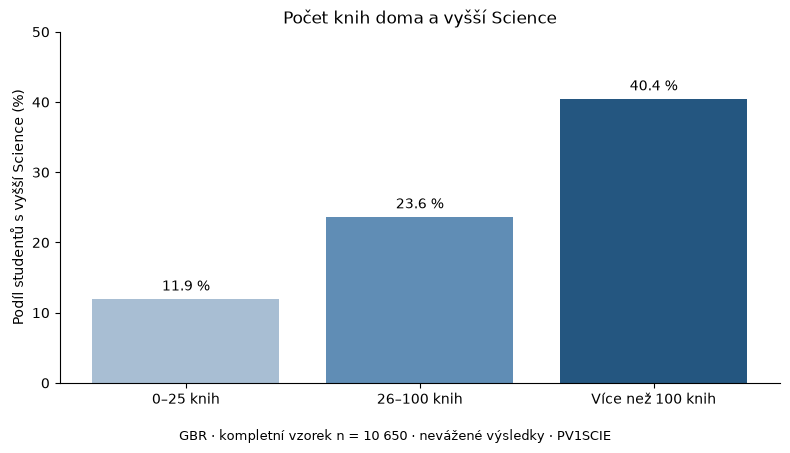

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    ["0–25 knih", "26–100 knih", "Více než 100 knih"],
    table["vyssi_science_pct"],
    color=["#A8BED3", "#608DB5", "#245680"],
)

ax.bar_label(bars, fmt="%.1f %%", padding=4)
ax.set_ylabel("Podíl studentů s vyšší Science (%)")
ax.set_ylim(0, 50)
ax.set_title("Počet knih doma a vyšší Science")
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.01,
    "GBR · kompletní vzorek n = 10 650 · nevážené výsledky · PV1SCIE",
    ha="center", fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()